# EDA – Palmer Penguins

Mục tiêu: hiểu dữ liệu để quyết định chọn đặc trưng và tiền xử lý cho model.

**Chỉ dùng `train.csv`.** Tập test được giữ kín tới cuối, không nhìn vào để tránh các quyết định bị ảnh hưởng bởi test.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Chạy được dù mở notebook từ ml/notebooks, ml/ hay thư mục gốc project
DATA_DIR = next(p for p in [Path("../data/processed"), Path("data/processed"), Path("ml/data/processed")] if p.exists())
df = pd.read_csv(DATA_DIR / "train.csv")

SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
COLORS = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}
MARKERS = {"Adelie": "o", "Chinstrap": "^", "Gentoo": "s"}

plt.rcParams.update({
    "figure.figsize": (7, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "axes.axisbelow": True,
})

print(f"Số row train: {len(df)}")
df.head()

Số row train: 266


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Gentoo,Biscoe,44.9,13.3,213,5100,female,2008
1,Chinstrap,Dream,50.7,19.7,203,4050,male,2009
2,Gentoo,Biscoe,48.8,16.2,222,6000,male,2009
3,Adelie,Torgersen,41.4,18.5,202,3875,male,2009
4,Adelie,Dream,37.6,19.3,181,3300,female,2007


## 1. Số lượng từng loài

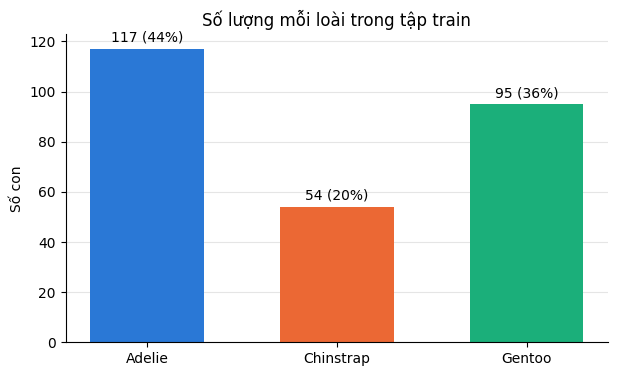

In [ ]:
counts = df["species"].value_counts().reindex(SPECIES)

fig, ax = plt.subplots()
bars = ax.bar(counts.index, counts.values, color=[COLORS[s] for s in counts.index], width=0.6)
ax.bar_label(bars, labels=[f"{v} ({v / len(df):.0%})" for v in counts.values], padding=3)
ax.set_title("Số lượng mỗi loài trong tập train")
ax.set_ylabel("Số con")
ax.grid(axis="x", visible=False)
plt.show()

**Nhận xét:** Adelie nhiều nhất (117 con, 44%), Chinstrap ít nhất (54 con, 20%), ít hơn khoảng một nửa Adelie.
Dữ liệu hơi lệch nhưng không nghiêm trọng. Khi đánh giá nên xem thêm F1 macro và recall theo từng loài, không chỉ accuracy, để chắc Chinstrap không bị model bỏ qua.

In [ ]:
def plot_by_species(column, label):
    """Vẽ boxplot kèm từng điểm dữ liệu của một cột số theo từng loài."""
    groups = [df.loc[df["species"] == s, column] for s in SPECIES]
    rng = np.random.default_rng(0)

    fig, ax = plt.subplots()
    ax.boxplot(groups, widths=0.5, showfliers=False,
               medianprops={"color": "#333333", "linewidth": 2},
               boxprops={"color": "#888888"}, whiskerprops={"color": "#888888"}, capprops={"color": "#888888"})
    for i, (s, values) in enumerate(zip(SPECIES, groups), start=1):
        x = i + rng.uniform(-0.15, 0.15, len(values))
        ax.scatter(x, values, s=14, alpha=0.6, color=COLORS[s], marker=MARKERS[s])
    ax.set_xticks(range(1, len(SPECIES) + 1), SPECIES)
    ax.set_title(f"{label} theo loài")
    ax.set_ylabel(label)
    ax.grid(axis="x", visible=False)
    plt.show()

    return df.groupby("species")[column].describe()[["min", "25%", "50%", "75%", "max"]].reindex(SPECIES)

## 2. Chiều dài mỏ theo loài

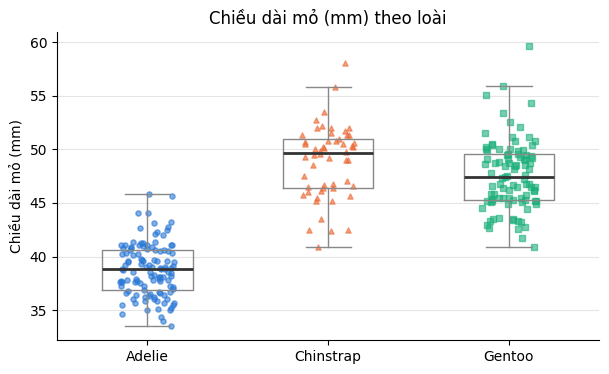

,min,25%,50%,75%,max
species,,,,,
Adelie,33.5,36.900,38.80,40.60,45.8
Chinstrap,40.9,46.425,49.65,50.95,58.0
Gentoo,40.9,45.300,47.40,49.55,59.6


In [ ]:
plot_by_species("bill_length_mm", "Chiều dài mỏ (mm)")

**Nhận xét:** Adelie có mỏ ngắn rõ rệt (trung vị 38,8 mm) so với Chinstrap (49,7 mm) và Gentoo (47,4 mm).
Chỉ riêng đặc trưng này đã tách được Adelie, nhưng Chinstrap và Gentoo chồng lấn nhiều nên cần thêm đặc trưng khác.

## 3. Độ sâu mỏ theo loài

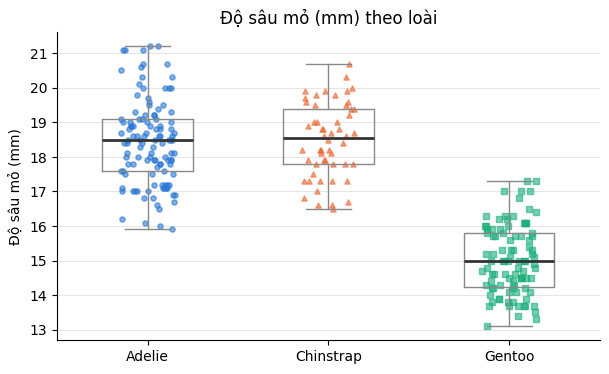

,min,25%,50%,75%,max
species,,,,,
Adelie,15.9,17.60,18.50,19.1,21.2
Chinstrap,16.5,17.80,18.55,19.4,20.7
Gentoo,13.1,14.25,15.00,15.8,17.3


In [ ]:
plot_by_species("bill_depth_mm", "Độ sâu mỏ (mm)")

**Nhận xét:** Gentoo có mỏ mỏng hơn hẳn (trung vị 15,0 mm), còn Adelie và Chinstrap gần như giống nhau (khoảng 18,5 mm).
Đặc trưng này tách được Gentoo và bổ sung cho chiều dài mỏ ở biểu đồ trên.

## 4. Chiều dài chân chèo theo loài

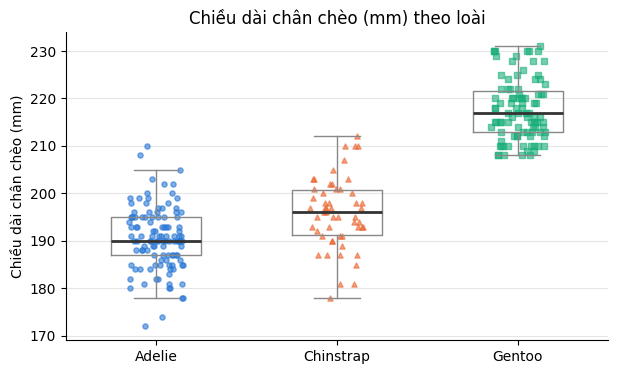

,min,25%,50%,75%,max
species,,,,,
Adelie,172.0,187.00,190.0,195.00,210.0
Chinstrap,178.0,191.25,196.0,200.75,212.0
Gentoo,208.0,213.00,217.0,221.50,231.0


In [ ]:
plot_by_species("flipper_length_mm", "Chiều dài chân chèo (mm)")

**Nhận xét:** Gentoo có chân chèo dài nhất và gần như không chồng lấn với hai loài còn lại (Gentoo thấp nhất 208 mm, trong khi 75% Chinstrap dưới 201 mm).
Adelie và Chinstrap chồng lấn nhiều, Chinstrap chỉ nhỉnh hơn một chút.

## 5. Khối lượng cơ thể theo loài

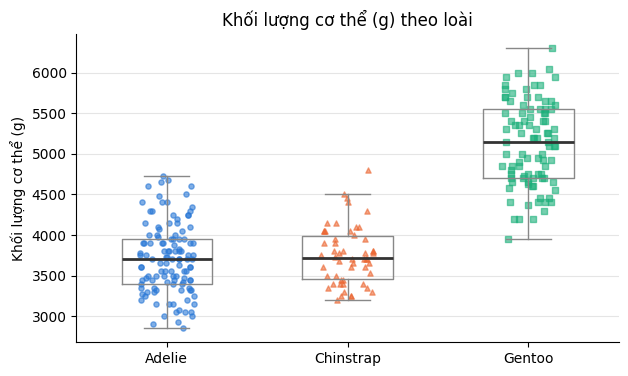

,min,25%,50%,75%,max
species,,,,,
Adelie,2850.0,3400.0,3700.0,3950.0,4725.0
Chinstrap,3200.0,3462.5,3712.5,3987.5,4800.0
Gentoo,3950.0,4700.0,5150.0,5550.0,6300.0


In [ ]:
plot_by_species("body_mass_g", "Khối lượng cơ thể (g)")

**Nhận xét:** Gentoo nặng hơn rõ rệt (trung vị 5.150 g so với khoảng 3.700 g của hai loài kia). Adelie và Chinstrap gần như trùng nhau.
Khối lượng có tương quan cao với chiều dài chân chèo (r ≈ 0,88), nên hai đặc trưng này mang thông tin gần giống nhau: đều chỉ giúp tách Gentoo.

## 6. Chiều dài mỏ và độ sâu mỏ

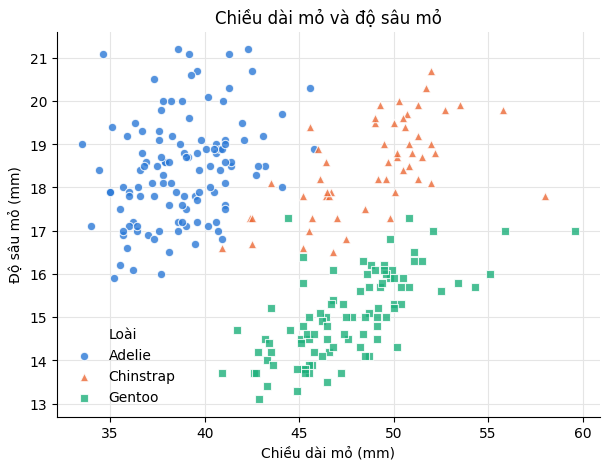

Tương quan chung: -0.25
Tương quan trong Adelie: 0.31
Tương quan trong Chinstrap: 0.61
Tương quan trong Gentoo: 0.67


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for s in SPECIES:
    part = df[df["species"] == s]
    ax.scatter(part["bill_length_mm"], part["bill_depth_mm"], label=s, color=COLORS[s],
               marker=MARKERS[s], s=36, alpha=0.8, edgecolors="white", linewidths=0.8)
ax.set_title("Chiều dài mỏ và độ sâu mỏ")
ax.set_xlabel("Chiều dài mỏ (mm)")
ax.set_ylabel("Độ sâu mỏ (mm)")
ax.legend(title="Loài", frameon=False)
plt.show()

print(f"Tương quan chung: {df['bill_length_mm'].corr(df['bill_depth_mm']):.2f}")
for s in SPECIES:
    part = df[df["species"] == s]
    print(f"Tương quan trong {s}: {part['bill_length_mm'].corr(part['bill_depth_mm']):.2f}")

**Nhận xét:** Khi kết hợp hai số đo mỏ, ba loài tách thành ba cụm khá rõ: Adelie (mỏ ngắn, sâu), Chinstrap (mỏ dài, sâu), Gentoo (mỏ dài, mỏng). Đây là cặp đặc trưng quan trọng nhất cho model.
Tương quan chung là âm (-0,25), nhưng trong từng loài lại dương (0,31 đến 0,67). Đây là nghịch lý Simpson: nếu bỏ qua loài thì sẽ rút ra kết luận sai về quan hệ giữa hai số đo.

## 7. Loài theo đảo (bổ sung)

In [ ]:
table = pd.crosstab(df["species"], df["island"]).reindex(SPECIES)
table

island,Biscoe,Dream,Torgersen
species,,,
Adelie,33,45,39
Chinstrap,0,54,0
Gentoo,95,0,0


**Nhận xét:** Trong dữ liệu này, Gentoo chỉ sống ở Biscoe, Chinstrap chỉ ở Dream, còn Adelie có ở cả 3 đảo.
Vì vậy `island` gần như "tiết lộ" đáp án. Model dùng nó sẽ hoạt động tốt trên bộ dữ liệu này, nhưng sẽ dự đoán sai nếu gặp chim ở một đảo khác. Nên cân nhắc thử model có và không có `island`.

## Kết luận cho bước huấn luyện

- **Đặc trưng chính:** 4 số đo cơ thể. Cặp mỏ (dài, sâu) tách được cả 3 loài; chân chèo và khối lượng tách được Gentoo.
- **Scaling:** các cột có đơn vị rất khác nhau (mm so với g, khối lượng lớn hơn khoảng 100 lần), nên cần `StandardScaler` cho các model dựa trên khoảng cách hoặc hệ số (KNN, SVM, Logistic Regression). Scaler phải được fit trên train, tốt nhất đặt trong `Pipeline`.
- **`island`:** tách loài quá mạnh vì mỗi đảo gần như chỉ có một số loài nhất định, nên cần so sánh model có và không có nó.
- **`year`:** đề xuất không dùng làm đặc trưng, vì đây là năm quan sát, không phải đặc điểm của chim.
- **Đánh giá:** lớp hơi lệch, nên dùng F1 macro và confusion matrix, cùng với cross-validation có stratify trên tập train.